## Visco-resistive tearing with shear flow: $\gamma(P_m,\alpha,k)$, $k_{max}$ by Newton, and what viscosity does to the shear suppression

**Rung 2b item 1 of `plans/AUTODIFF_PLAN.md`.** The paper (Mallet, Eriksson, Swisdak & Juno, JPP 91 E146 (2025), sec. 2) set
$\nu=0$ and left viscosity as future work. Here $\nu>0$: `diss` $=(\nu,\eta)=(P_m/S,\,1/S)$, everything else as rung 2
(`tearing-kmax.ipynb`): `dims=2`, `hyper=1`, $a=v_{Ay}=1$, $\Psi_0=\mathrm{sech}^2x$ (+2 images, $f=\Psi_0'$, $|f'(0)|=2$,
$\Delta'a\simeq15/(ka)^2$, i.e. $n=2$), $\Phi_0=\alpha\Psi_0$, the $k_y$ block, fp64. Dimensionless Alfvén units throughout.

**Both $k$ and `diss` are overrides**: one `Parameters` per $(S,n_x,L_x)$ serves every $k$, $P_m$ and $\alpha$
(`overrides={"Ly": 2π/k, "diss": (Pm/S, 1/S)}`; $J$ there equals $J$ of a `Parameters` built at that point, 0.0 difference --
`tests/test_tearing_viscosity.py`). Each eigen-solve gives four sensitivities from one right/left pair,
$d\lambda/dp=w^H(\partial_pJ)v/w^Hv$: $\partial_\eta$ (`dparams={"diss": (0, 1)}`, $\nu$ held), $\partial_\nu$ (`(1, 0)`, $\eta$ held),
$\partial_k$ (`{"Ly": -Ly/k}`) and $\partial_\alpha$ ($dx_0=(\Psi_0,0)$). Local exponents, one solve each:
$$q_{P_m}=\frac{\partial\ln\gamma}{\partial\ln P_m}\Big|_S=\frac{\nu\gamma_\nu}{\gamma},\qquad
q_S=\frac{\partial\ln\gamma}{\partial\ln S}\Big|_{P_m}=-\frac{\eta\gamma_\eta+\nu\gamma_\nu}{\gamma},\qquad
q_k=\frac{k\gamma_k}{\gamma}.$$
Data: `tearing_viscosity_run.py` (every solve one cache file under `examples/data/tearing-viscosity/`); this notebook only
reads that cache and the cached theory tables.

### 0. Theory at $\alpha=0$: the visco-resistive inner layer, solved exactly

Linearised RMHD near the resonant surface ($f\simeq f'x$, $\partial_x\gg k$) with $\gamma$, $\eta$ and $\nu$:
$$\gamma\psi-ikf'x\,\phi=\eta\psi'',\qquad \gamma\phi''-\nu\phi''''=ikf'x\,\psi''.$$
In B&L 2018's inner variables ($s=x/\delta_\eta$, $\delta_\eta=(\eta/k|f'|)^{1/3}$, $\Lambda=\gamma/(\eta^{1/3}(k|f'|)^{2/3})$,
$\phi=-iu$; the same variables as rung 1a's `T._inner_bvp`) this is
$$\psi''=\Lambda\psi-s\,u,\qquad P_m\,u''''=\Lambda u''+s\,\psi'' ,$$
$\psi$ even, $u$ odd ($u(0)=u''(0)=0$), and in the far field the ideal branch $u=\Lambda\psi/s$ (two conditions at $s_{max}$ suppress
the two growing viscous exponentials). Matching $\psi\to c_0+c_1s$ gives the **exact layer relation**
$$\Delta'\delta_\eta=F(\Lambda,P_m)=2c_1/c_0,$$
which at $P_m=0$ is B&L's Gamma-function relation (rung 1a) -- the deviation is linear in $P_m$. It is solved numerically
(`solve_bvp`, Richardson in $s_{max}$), tabulated per $P_m$ in $r=\Lambda/\Lambda_{pole}(P_m)$ and inverted by a spline.
**Large $P_m$** (inertia negligible, $\gamma\delta_v^2/\nu=\Lambda P_m^{-2/3}\ll1$): with $s=P_m^{1/6}t$, $\Lambda=P_m^{-1/3}L$,
$u=P_m^{-1/2}v$ the layer loses $P_m$: $\psi''=L\psi-tv$, $v''''=t(L\psi-tv)$, so $F\to P_m^{-1/6}F_v(\Lambda P_m^{1/3})$ with
the inertia-free relation $F_v$. Its two limits (Porcelli 1987):

* **viscous constant-$\psi$** ($L\to0$): $F_v\to I_VL$ with
  $I_V=\int(1-sU)ds$, $U''''+s^2U=s$. In Fourier space ($\hat U''=\kappa^4\hat U$ away from $\kappa=0$, $\hat U\propto
  \mathrm{sgn}\,\kappa\,|\kappa|^{1/2}K_{1/6}(|\kappa|^3/3)$, the jump fixed by $s\leftrightarrow2\pi i\delta'(\kappa)$)
  $$I_V=\pi\,6^{-1/3}\,\Gamma(5/6)/\Gamma(7/6)=2.1036\ldots$$
  (the same calculation with $\kappa^2$ gives FKR's $C_{FKR}=(\pi/2)\Gamma(3/4)/\Gamma(5/4)$ -- `const_psi_integral(m)`;
  $I_V$ is checked against an independent ODE solution in the test file):
  $\gamma=\Delta'\eta^{5/6}\nu^{-1/6}(kf')^{1/3}/I_V\ \propto S^{-2/3}P_m^{-1/6}(ka)^{-5/3}$;
* **viscous nonconstant-$\psi$** (the pole $L^*=C_{VC}$ of $F_v$): $\gamma=C_{VC}\,\eta^{2/3}\nu^{-1/3}(kf')^{2/3}\propto
  S^{-1/3}P_m^{-1/3}(ka)^{2/3}$;
* their crossing, for $\Delta'a\propto(ka)^{-n}$: $k_{max}\propto S^{-1/(3n+1)}P_m^{1/(2(3n+1))}$,
  $\gamma_{max}\propto S^{-1/3-2/(3(3n+1))}P_m^{-1/3+1/(3(3n+1))}$ -- for $n=1$ the familiar $S^{-1/4}P_m^{1/8}$, $S^{-1/2}P_m^{-1/4}$;
  **for this $n=2$ sheet $k_{max}\propto S^{-1/7}P_m^{1/14}$, $\gamma_{max}\propto S^{-3/7}P_m^{-2/7}$**. The $S$-exponents at fixed
  $P_m$ are the inviscid ones (rung 2); only the $P_m$-exponents discriminate.

Local exponents of the exact relation, with $m=\partial\ln F/\partial\ln\Lambda$, $\mu=\partial\ln F/\partial\ln P_m|_\Lambda$:
$q_{P_m}=-\mu/m$, $q_S|_{P_m}=-\tfrac13-\tfrac1{3m}$, $q_k=\tfrac23+(d\ln\Delta'/d\ln k-\tfrac13)/m$.

**Shear ($\alpha>0$): three scaling arguments, none of them a theory.** No inner-layer solution with shear exists even at
$\nu=0$ (the paper's sec. 5 is a scaling argument); these are the hypotheses the data are tested against.

1. *Inner layer, shear-dominated.* Write $\Phi=\alpha\Psi+\chi$ in the paper's inner equations (4.3)-(4.4) with the viscous term
   added, $(\delta+i\alpha x)\Phi''-ix\Psi''=\delta_\nu^3\Phi''''$ ($\delta_\nu^3=\nu a/kv_{Ay}=P_m\delta_\eta^3$). Ohm's law gives
   $\chi=(\delta\Psi-\delta_\eta^3\Psi'')/ix$ exactly, and the vorticity equation becomes
   $\delta\alpha\Psi''-i(1-\alpha^2)x\Psi''+(\delta+i\alpha x)\chi''-\delta_\nu^3\chi''''-\alpha\delta_\nu^3\Psi''''=0$: in the layer the
   resistive term ($i\alpha x\chi''\sim\alpha\delta_\eta^3\Psi/w^4$) and the viscous one ($\alpha\delta_\nu^3\Psi/w^4$) are of the SAME
   form, relative weight $P_m$. So in the shear-modified regime the paper's width (5.1) becomes
   $w^3\sim\alpha(\delta_\eta^3+c\,\delta_\nu^3)/(1-\alpha^2)$ ($c=O(1)$) and its nonconstant-$\psi$ rate (5.11)
   $\gamma\sim\alpha^{1/3}(1-\alpha^2)^{2/3}(ka)^{2/3}[(\eta+c\nu)a/v_{Ay}]^{1/3}$: **viscosity widens the layer and RAISES $\gamma$**,
   $q_{P_m}=\tfrac13\,cP_m/(1+cP_m)>0$ and $\gamma_\nu/\gamma_\eta\to c>0$ -- the opposite sign to the no-flow $-1/6$, $-1/3$.
   (Viscosity also enters the matching integral (4.5), at relative order $P_m/(1+P_m)$: $c$ and the prefactor are not predicted.)
2. *Where the shear layer takes over.* Shear modifies the layer once $\gamma$ is small against the shear rate across it
   (eq. 4.13, $\lambda\ll\alpha$). In the viscous nonconstant-$\psi$ layer $\gamma/(\alpha kf'\delta_v)=C_{VC}P_m^{-1/2}/\alpha$ ($\delta_v=
   (\eta\nu/(kf')^2)^{1/6}$), against $\sim1/\alpha$ inviscid: at large $P_m$ the crossover to item 1's regime should move to
   $\alpha\sim C_{VC}P_m^{-1/2}$ -- measured below through the small-$\alpha$ coefficient $c_2$ of
   $\gamma_{max}(\alpha)/\gamma_{max}(0)=1-c_2\alpha^2+\ldots$ ($c_2>0$: suppression; $c_2<0$: shear destabilises).
3. *Outer viscous damping.* The outer flow $\Phi=\alpha\Psi$ on scale $1/k$ is damped at $\nu k^2$, which the shear-suppressed growth rate
   $\gamma\sim(1-\alpha^2)^{4/7}S^{-3/7}$ (eq. 5.14, $k_{max}\sim(1-\alpha^2)^{-1/7}S^{-1/7}$) eventually falls below as $\alpha\to1$. Setting
   $\gamma_{max}\sim\nu k_{max}^2=P_mk_{max}^2/S$ gives a viscous stability boundary
   $$1-\alpha_c^2\sim P_m^{7/6}/S\qquad(n=2),$$
   so at fixed $P_m$ the mode is stable for $\alpha>\alpha_c$ and $\alpha_c\to1$ as $S\to\infty$; near it $\gamma_{max}$ must GROW with $S$ at
   fixed $P_m$ ($q_S>0$), unlike every inviscid regime.

In [1]:
import os
os.environ["TARANIS_PRECISION"] = "64"
os.environ.setdefault("TARANIS_VISC_PROFILE", "full")
import time
import numpy as np
import matplotlib.pyplot as plt
import tearing_eigen_run as T
import tearing_rung2_run as R
import tearing_viscosity_run as V

t0 = time.time()
FD = V.fd_results()
DISP = {(S, Pm): V.disp_results(S, Pm) for S in V.S_DISP for Pm in V.PM_DISP}
DISPS = {(S, al, Pm): V.disp_results(S, Pm, al) for (S, al) in V.DISP_SHEAR for Pm in V.PM_DISP}
KP = {S: V.kmax_Pm_results(S) for S in V.S_CHAIN}
KPS = {(S, al): V.kmax_Pm_results(S, al) for (S, al) in V.CHAIN_SHEAR}
KA = {(S, Pm): V.kmax_alpha_results(S, Pm) for S in V.PM_KA for Pm in V.PM_KA[S]}
KA.update({(S, Pm): V.kmax_alpha_results(S, Pm) for S, (pms, _) in V.KA_HI.items() for Pm in pms})
G2 = V.grid2_results()
BR = V.branch_results()
C2 = V.c2_results()
# rung 2 (nu = 0), same boxes: dispersion sweeps and k_max chains (read-only)
R2D = {S: R.disp_results(S, 0.0) for S in V.S_DISP}
R2KA = {S: R.kmax_alpha_results(S) for S in (1e3, 1e4, 1e5)}
nd = sum(len(v.get(1, {})) for v in DISP.values())
print(f"profile {V.PROFILE}: {nd} alpha=0 dispersion points, {sum(len(v.get(1, {})) for v in DISPS.values())} shear ones, "
      f"{sum(len(v) for v in KP.values())} k_max(Pm), {sum(len(v) for v in KPS.values())} k_max(Pm) with shear, "
      f"{sum(len(v) for v in KA.values())} k_max(alpha), {len(G2)} 2nx, {len(FD)} FD points, {len(BR)} branch scans, "
      f"{len(C2)} c2 points ({time.time() - t0:.1f} s)")

field variables are using 64bit precision.
profile full: 94 alpha=0 dispersion points, 31 shear ones, 24 k_max(Pm), 8 k_max(Pm) with shear, 48 k_max(alpha), 2 2nx, 3 FD points, 17 branch scans, 27 c2 points (5.7 s)


### 1. Checks: the layer relation's limits, the FD gate

In [2]:
print(f"I_V = pi 6^(-1/3) Gamma(5/6)/Gamma(7/6) = {V.I_V:.10f};  const_psi_integral(1) = {V.const_psi_integral(1):.10f} "
      f"= C_FKR {T.C_FKR:.10f};  C_VC (pole of F_v) = {V.c_vcoppi():.10f}")
print("\nF(Lam, Pm)/F_B&L(Lam) - 1 at small Pm (linear in Pm), and F Pm^(1/6)/F_v(Lam Pm^(1/3)) - 1 at large Pm:")
for lam in (0.1, 0.5):
    print(f"  Lam = {lam}: " + "   ".join(f"Pm={p:g}: {V.inner_F_visc(lam, p)/T.inner_F(lam) - 1:+.3e}" for p in (3e-3, 1e-2, 3e-2)))
Fv = V.inner_F_visc(0.5, 1.0, inertia=False)
print("  L = Lam Pm^(1/3) = 0.5: " + "   ".join(f"Pm={p:g}: {V.inner_F_visc(0.5*p**(-1/3), p)*p**(1/6)/Fv - 1:+.2e}" for p in (10, 100, 1000)))
print("  F_v(L)/L -> I_V: " + "  ".join(f"L={L:g}: {V.inner_F_visc(L, 1.0, inertia=False)/L:.7f}" for L in (1e-2, 1e-3, 1e-4)))
print("\nthe pole Lam_pole(Pm) (nonconstant-psi limit) and Lam_pole Pm^(1/3) -> C_VC:")
for p in (0.1, 1.0, 10.0, 100.0):
    lp = np.exp(V.theory_table(p)[0])
    print(f"  Pm = {p:6g}: Lam_pole = {lp:.6f}   Lam_pole Pm^(1/3) = {lp*p**(1/3):.6f}")

I_V = pi 6^(-1/3) Gamma(5/6)/Gamma(7/6) = 2.1035920740;  const_psi_integral(1) = 2.1236482730 = C_FKR 2.1236482730;  C_VC (pole of F_v) = 1.5255363653

F(Lam, Pm)/F_B&L(Lam) - 1 at small Pm (linear in Pm), and F Pm^(1/6)/F_v(Lam Pm^(1/3)) - 1 at large Pm:
  Lam = 0.1: Pm=0.003: +2.544e-02   Pm=0.01: +7.042e-02   Pm=0.03: +1.554e-01
  Lam = 0.5: Pm=0.003: +3.545e-03   Pm=0.01: +1.157e-02   Pm=0.03: +3.291e-02
  L = Lam Pm^(1/3) = 0.5: Pm=10: +2.90e-02   Pm=100: +2.88e-03   Pm=1000: +2.88e-04
  F_v(L)/L -> I_V: L=0.01: 2.1161733  L=0.001: 2.1048426  L=0.0001: 2.1037171

the pole Lam_pole(Pm) (nonconstant-psi limit) and Lam_pole Pm^(1/3) -> C_VC:
  Pm =    0.1: Lam_pole = 0.984649   Lam_pole Pm^(1/3) = 0.457034
  Pm =      1: Lam_pole = 0.895248   Lam_pole Pm^(1/3) = 0.895248
  Pm =     10: Lam_pole = 0.625016   Lam_pole Pm^(1/3) = 1.346556
  Pm =    100: Lam_pole = 0.323580   Lam_pole Pm^(1/3) = 1.501925


In [3]:
print("theory k_max(S, Pm) of the exact layer relation and its running exponents (n = 2 asymptotes: k_S -1/7, k_Pm 1/14, "
      "g_S -3/7, g_Pm -2/7)")
print("    S     Pm   | k_max      gamma_max     | dlnk/dlnS  dlnk/dlnPm | dlng/dlnS  dlng/dlnPm")
for S in (1e3, 1e5, 1e8):
    for Pm in (0.1, 1.0, 10.0, 100.0):
        k, g = V.theory_kmax_visc(S, Pm)
        sl = V.theory_kmax_slopes_visc(S, Pm)
        print(f"  {S:.0e}  {Pm:5g} | {k:.6f}  {g:.6e} | {sl['k_S']:+.5f}   {sl['k_Pm']:+.5f}   | {sl['g_S']:+.5f}   {sl['g_Pm']:+.5f}")

theory k_max(S, Pm) of the exact layer relation and its running exponents (n = 2 asymptotes: k_S -1/7, k_Pm 1/14, g_S -3/7, g_Pm -2/7)
    S     Pm   | k_max      gamma_max     | dlnk/dlnS  dlnk/dlnPm | dlng/dlnS  dlng/dlnPm
  1e+03    0.1 | 0.625763  8.356404e-02 | -0.13730   -0.01829   | -0.42743   -0.02409
  1e+03      1 | 0.584824  7.295505e-02 | -0.13873   -0.03468   | -0.42772   -0.10693
  1e+03     10 | 0.564950  4.932448e-02 | -0.13915   +0.01591   | -0.42784   -0.22867
  1e+03    100 | 0.623609  2.710167e-02 | -0.13718   +0.06007   | -0.42745   -0.27840
  1e+05    0.1 | 0.326991  1.163068e-02 | -0.14256   -0.01913   | -0.42853   -0.02424
  1e+05      1 | 0.304849  1.014932e-02 | -0.14267   -0.03567   | -0.42855   -0.10714
  1e+05     10 | 0.294279  6.860586e-03 | -0.14270   +0.01644   | -0.42856   -0.22859
  1e+05    100 | 0.325928  3.771989e-03 | -0.14256   +0.06246   | -0.42854   -0.27792
  1e+08    0.1 | 0.121915  6.023905e-04 | -0.14288   -0.01918   | -0.42858   -0.02424
 

In [4]:
print("(c) FD gate: central differences of eigenvalues (relative steps h in eta, nu, k) vs the sensitivity")
print("    S      ka   alpha  Pm   | dir |  sensitivity          | h        |FD - sens|/|sens|  | order")
FDROWS = []
for (S, ka, al, Pm), (rec, rows) in FD.items():
    for which in ("eta", "nu", "k"):
        d = complex(rec["dlam_" + which]).real
        hs = np.array([r[0] for r in rows[which]]); es = np.array([r[2] for r in rows[which]])
        order = np.polyfit(np.log(hs), np.log(es), 1)[0]
        FDROWS.append((S, ka, al, Pm, which, order, es[-1]/abs(d)))
        print(f"  {S:.0e}  {ka:4.2f}  {al:4.2f}  {Pm:5g} | {which:3s} | {d:+.12e} | " +
              "  ".join(f"{hh:.0e}:{e/abs(d):.1e}" for hh, e in zip(hs, es)) + f" | {order:.3f}")
    print(f"{'':30s}gamma = {complex(rec['lam']).real:.10e}, residuals {float(rec['res_r']):.1e}/{float(rec['res_l']):.1e}, "
          f"kappa {float(rec['kappa']):.2e}")

(c) FD gate: central differences of eigenvalues (relative steps h in eta, nu, k) vs the sensitivity
    S      ka   alpha  Pm   | dir |  sensitivity          | h        |FD - sens|/|sens|  | order
  1e+03  0.50  0.00      1 | eta | +3.017341562067e+01 | 1e-02:2.0e-05  3e-03:1.8e-06  1e-03:2.0e-07 | 2.000
  1e+03  0.50  0.00      1 | nu  | -7.278081231379e+00 | 1e-02:1.2e-05  3e-03:1.1e-06  1e-03:1.2e-07 | 2.000
  1e+03  0.50  0.00      1 | k   | +2.246821974916e-02 | 1e-02:9.9e-05  3e-03:8.9e-06  1e-03:9.9e-07 | 2.000
                              gamma = 6.5254250707e-02, residuals 3.0e-15/1.2e-14, kappa 6.08e+00
  1e+04  0.30  0.80     10 | eta | +2.591293830819e+01 | 1e-02:2.4e-06  3e-03:2.1e-07  1e-03:2.4e-08 | 2.000
  1e+04  0.30  0.80     10 | nu  | +1.902691664924e-01 | 1e-02:3.0e-04  3e-03:2.7e-05  1e-03:3.0e-06 | 2.000
  1e+04  0.30  0.80     10 | k   | +1.866737972136e-02 | 1e-02:7.2e-06  3e-03:6.5e-07  1e-03:7.2e-08 | 2.000
                              gamma = 1.0605479034e

**Result (section 1).** The layer relation has the limits it should. $I_V=\pi6^{-1/3}\Gamma(5/6)/\Gamma(7/6)=2.1035920740$, and the
same formula at $m=1$ returns $C_{FKR}=2.1236482730$. The inertia-free layer gives $F_v(L)/L=2.1037171$ at $L=10^{-4}$, approaching
$I_V$. The pole is $C_{VC}=1.5255363653$, and $\Lambda_{pole}P_m^{1/3}=1.501925$ at $P_m=100$. At small $P_m$ the deviation from
B&L vanishes linearly as $P_m\to0$ (gated in the test file at $P_m\le10^{-2}$). Over $P_m=0.003$–0.03 it is already sublinear: $3.545\times10^{-3}$, $1.157\times10^{-2}$ and $3.291\times10^{-2}$ at $\Lambda=0.5$ (ratios 3.26 and 2.84 for steps of 3.33 and 3), and more so at $\Lambda=0.1$.
At large $P_m$ the departure from the inertia-free form falls as $1/P_m$: $2.90\times10^{-2}$, $2.88\times10^{-3}$, $2.88\times10^{-4}$.

The exact relation's running exponents at the maximum depend on the regime:

* At $S=10^8$, $P_m=100$ they are $d\ln k_{max}/d\ln P_m=+0.06261$ and $d\ln\gamma_{max}/d\ln P_m=-0.27790$. They are still
  approaching the large-$P_m$ asymptotes $1/14=0.0714$ and $-2/7=-0.2857$.
* The $S$-exponents at fixed $P_m$ are $-0.14288$ and $-0.42858$ at $S=10^8$ for every $P_m$, i.e. the inviscid $-1/7$, $-3/7$.
* $k_{max}(P_m)$ is not monotonic. $d\ln k_{max}/d\ln P_m$ is $-0.035$ near $P_m=1$ and $+0.016$ at $P_m=10$.

FD gate: in all 9 cases ($\partial_\eta$, $\partial_\nu$, $\partial_k$ at three points, two of them with shear: $\alpha=0.8$, $P_m=10$ and $\alpha=0.6$, $P_m=0.1$) the
eigenvalue central differences converge onto the sensitivity at order 2.000. At $h=10^{-3}$ they agree to between
$2.4\times10^{-8}$ and $3.0\times10^{-6}$ relative.

### 2. $\alpha=0$: $\gamma(k)$ and its local exponents against the exact layer relation

Sweeps at $S=10^3,10^4,10^5$, $P_m=0.1,1,10,100$ (and rung 2's $P_m=0$ on the same boxes), rung 1a's per-$k$ box, every point
also at $n_x/2$. The layer relation is asymptotic in $S$ at fixed $P_m$: agreement is a trend.

In [5]:
def curve(D, lv=1):
    f = D.get(lv, {})
    ka = np.array(sorted(f))
    return ka, [f[k] for k in ka]

print("grid convergence (nx vs nx/2, max over ka) and the worst residual / kappa per sweep")
print("    S      Pm   | pts | max rel d gamma  max |d q_Pm|  max |d q_S| | max res   max kappa")
for (S, Pm), D in sorted(DISP.items()):
    hi, lo = D.get(1, {}), D.get(2, {})
    com = [k for k in hi if k in lo]
    if not com:
        continue
    dg = max(abs(complex(hi[k]["lam"])/complex(lo[k]["lam"]) - 1) for k in com)
    dq = max(abs(V.q_Pm(hi[k]) - V.q_Pm(lo[k])) for k in com)
    ds = max(abs(V.q_S(hi[k]) - V.q_S(lo[k])) for k in com)
    res = max(max(float(hi[k]["res_r"]), float(hi[k]["res_l"])) for k in hi)
    print(f"  {S:.0e}  {Pm:5g} | {len(hi):3d} |   {dg:.1e}          {dq:.1e}       {ds:.1e}  | {res:.1e}   "
          f"{max(float(hi[k]['kappa']) for k in hi):.1e}")
missing = [(S, Pm, k) for (S, Pm) in DISP for k in V.KA_DISP if k not in DISP[(S, Pm)].get(1, {})]
print(f"\nnot available: {missing if missing else 'none'}")

grid convergence (nx vs nx/2, max over ka) and the worst residual / kappa per sweep
    S      Pm   | pts | max rel d gamma  max |d q_Pm|  max |d q_S| | max res   max kappa
  1e+03    0.1 |   8 |   2.3e-06          8.2e-06       2.1e-05  | 6.4e-13   6.8e+00
  1e+03      1 |   8 |   2.3e-08          6.8e-08       1.7e-07  | 4.3e-13   6.3e+00
  1e+03     10 |   7 |   6.4e-12          2.4e-11       5.1e-11  | 1.5e-13   5.6e+00
  1e+03    100 |   7 |   8.5e-14          9.6e-13       6.7e-13  | 8.3e-15   3.9e+00
  1e+04    0.1 |   8 |   1.8e-04          9.6e-05       8.2e-04  | 6.2e-13   1.8e+01
  1e+04      1 |   8 |   4.8e-06          1.4e-05       3.8e-05  | 6.5e-13   1.6e+01
  1e+04     10 |   8 |   7.2e-11          4.7e-10       9.7e-10  | 2.5e-13   1.5e+01
  1e+04    100 |   8 |   9.0e-12          8.9e-12       1.9e-11  | 1.8e-14   1.0e+01
  1e+05    0.1 |   8 |   6.7e-04          2.9e-04       2.7e-03  | 6.6e-13   4.8e+01
  1e+05      1 |   8 |   2.8e-05          7.8e-05       2.1e-0

In [6]:
print("gamma_eig/gamma_theory (exact visco-resistive layer) along the sweeps")
print("   ka  | " + " | ".join(f"S={S:.0e}: " + " ".join(f"Pm={p:<5g}" for p in V.PM_DISP) for S in V.S_DISP))
for ka in V.KA_DISP:
    row = []
    for S in V.S_DISP:
        cells_ = []
        for Pm in V.PM_DISP:
            r = DISP[(S, Pm)].get(1, {}).get(ka)
            cells_.append(f"{complex(r['lam']).real/V.gamma_theory_visc(ka, S, Pm):8.4f}" if r is not None else " "*8)
        row.append(" ".join(cells_))
    print(f"  {ka:4.2f} | " + " | ".join(row))

gamma_eig/gamma_theory (exact visco-resistive layer) along the sweeps
   ka  | S=1e+03: Pm=0.1   Pm=1     Pm=10    Pm=100   | S=1e+04: Pm=0.1   Pm=1     Pm=10    Pm=100   | S=1e+05: Pm=0.1   Pm=1     Pm=10    Pm=100  
  0.15 |   0.9016   0.8827   0.8140   0.6473 |   0.9730   0.9693   0.9573   0.9192 |   0.9922   0.9915   0.9895   0.9824
  0.30 |   0.9188   0.9056   0.8603   0.7341 |   0.9751   0.9722   0.9641   0.9378 |   0.9924   0.9917   0.9898   0.9838
  0.40 |   0.9208   0.9083   0.8669   0.7510 |   0.9753   0.9721   0.9633   0.9379 |   0.9927   0.9916   0.9888   0.9820
  0.60 |   0.9200   0.9053   0.8604   0.7472 |   0.9751   0.9698   0.9564   0.9273 |   0.9920   0.9895   0.9843   0.9751
  0.85 |   0.9131   0.8899   0.8306   0.7058 |   0.9703   0.9599   0.9390   0.9017 |   0.9885   0.9836   0.9752   0.9617
  1.25 |   0.8765   0.8271   0.7321   0.5665 |   0.9495   0.9270   0.8897   0.8303 |   0.9778   0.9675   0.9516   0.9274
  1.50 |   0.8263   0.7488   0.6164   0.4001 |   0.9247 

In [7]:
print("q_Pm = d ln gamma/d ln Pm |_S along gamma(k): eigen-sensitivity | exact layer relation")
for S in V.S_DISP:
    print(f"  S = {S:.0e}:   ka  | " + " | ".join(f"Pm={p:<5g} eig    th  " for p in V.PM_DISP))
    for ka in V.KA_DISP:
        row = []
        for Pm in V.PM_DISP:
            r = DISP[(S, Pm)].get(1, {}).get(ka)
            row.append(f"{V.q_Pm(r):+.4f} {V.theory_exponents(ka, S, Pm)['qPm']:+.4f}" if r is not None else " "*20)
        print(f"               {ka:4.2f} | " + " | ".join(row))

q_Pm = d ln gamma/d ln Pm |_S along gamma(k): eigen-sensitivity | exact layer relation
  S = 1e+03:   ka  | Pm=0.1   eig    th   | Pm=1     eig    th   | Pm=10    eig    th   | Pm=100   eig    th  
               0.15 | -0.0184 -0.0148 | -0.1020 -0.0845 | -0.2941 -0.2340 | -0.4592 -0.3164
               0.30 | -0.0187 -0.0161 | -0.1004 -0.0890 | -0.2722 -0.2336 | -0.4161 -0.3095
               0.40 | -0.0203 -0.0177 | -0.1047 -0.0941 | -0.2675 -0.2327 | -0.3991 -0.3018
               0.60 | -0.0264 -0.0232 | -0.1203 -0.1081 | -0.2634 -0.2274 | -0.3753 -0.2811
               0.85 | -0.0399 -0.0344 | -0.1457 -0.1273 | -0.2597 -0.2149 | -0.3575 -0.2519
               1.25 | -0.0764 -0.0616 | -0.1853 -0.1485 | -0.2674 -0.1938 | -0.3789 -0.2135
               1.50 | -0.1107 -0.0828 | -0.2154 -0.1559 | -0.3019 -0.1841 | -0.4944 -0.1967
               2.00 | -0.3790 -0.1353 | -1.3903 -0.1642 |                      |                     
  S = 1e+04:   ka  | Pm=0.1   eig    th   | Pm=1     eig

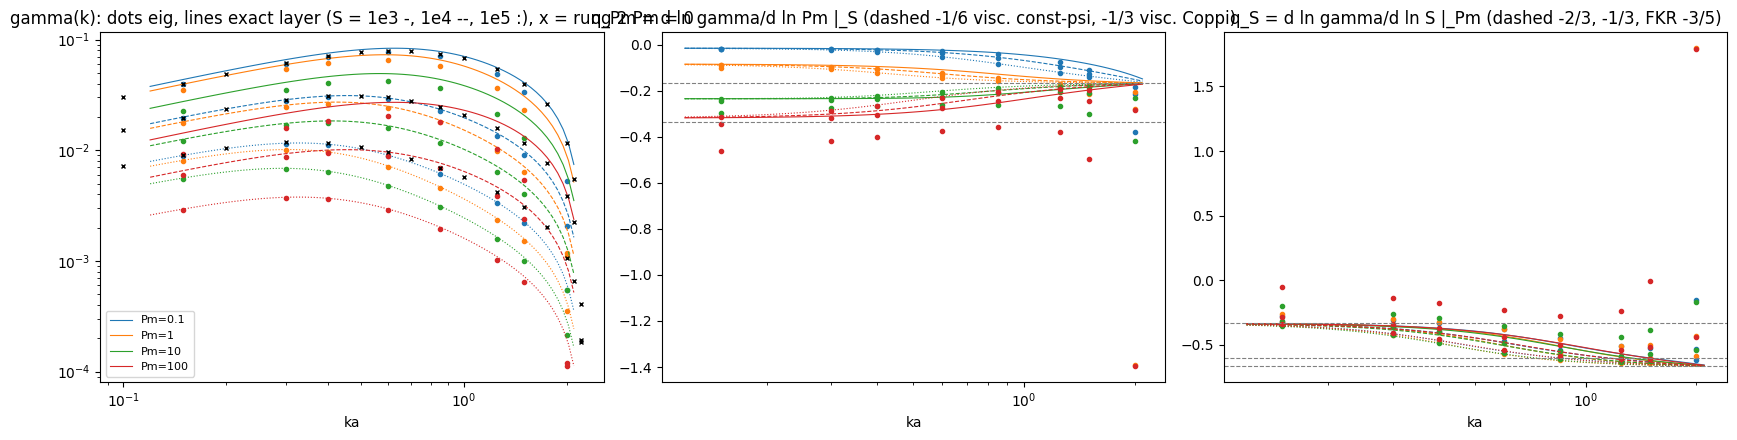

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for j, Pm in enumerate(V.PM_DISP):
    for ls, S in zip(("-", "--", ":"), V.S_DISP):
        ka, recs = curve(DISP[(S, Pm)])
        if not len(ka):
            continue
        kk = np.geomspace(0.12, 2.1, 80)
        axs[0].loglog(ka, [complex(r["lam"]).real for r in recs], "o", ms=3, color=f"C{j}")
        axs[0].loglog(kk, [V.gamma_theory_visc(k, S, Pm) for k in kk], ls, lw=0.8, color=f"C{j}",
                      label=f"Pm={Pm:g}" if S == V.S_DISP[0] else None)
        axs[1].semilogx(ka, [V.q_Pm(r) for r in recs], "o", ms=3, color=f"C{j}")
        axs[1].semilogx(kk, [V.theory_exponents(k, S, Pm)["qPm"] for k in kk], ls, lw=0.8, color=f"C{j}")
        axs[2].semilogx(ka, [V.q_S(r) for r in recs], "o", ms=3, color=f"C{j}")
        axs[2].semilogx(kk, [V.theory_exponents(k, S, Pm)["qS"] for k in kk], ls, lw=0.8, color=f"C{j}")
for S, ls in zip(V.S_DISP, ("-", "--", ":")):
    ka, recs = curve(R2D[S])
    axs[0].loglog(ka, [complex(r["lam"]).real for r in recs], "kx", ms=3)
for y in (-1/6, -1/3):
    axs[1].axhline(y, color="gray", ls="--", lw=0.8)
for y in (-2/3, -1/3, -3/5):
    axs[2].axhline(y, color="gray", ls="--", lw=0.8)
axs[0].set_title("gamma(k): dots eig, lines exact layer (S = 1e3 -, 1e4 --, 1e5 :), x = rung 2 Pm = 0")
axs[1].set_title("q_Pm = d ln gamma/d ln Pm |_S (dashed -1/6 visc. const-psi, -1/3 visc. Coppi)")
axs[2].set_title("q_S = d ln gamma/d ln S |_Pm (dashed -2/3, -1/3, FKR -3/5)")
axs[0].legend(fontsize=8)
for ax in axs:
    ax.set_xlabel("ka")
plt.tight_layout()

**Result (section 2).** The sweeps are grid-converged:

* For $P_m\ge10$ the $n_x$ and $n_x/2$ growth rates agree to $\le1.8\times10^{-10}$ at $S\ge10^4$.
* The worst case is $6.7\times10^{-4}$ ($S=10^5$, $P_m=0.1$). There the thin viscous sublayer inside the resistive layer sets the resolution.

The two missing points have no growing mode: $ka=2$ at $S=10^3$, $P_m=10$ and 100 (checked by a dense eigen-solve in review: largest eigenvalue $-1.87\times10^{-3}$ and $-3.90\times10^{-3}$, both real). Near the ideal marginal $ka=\sqrt5$, viscosity stabilises at low $S$.

**The eigenvalues converge onto the exact visco-resistive layer relation as $S$ grows, at every $P_m$.** At $ka=0.4$,
$\gamma_{eig}/\gamma_{th}$ is:

| $P_m$ | $S=10^3$ | $S=10^4$ | $S=10^5$ |
|---|---|---|---|
| 1 | 0.9083 | 0.9721 | 0.9916 |
| 100 | 0.7510 | 0.9379 | 0.9820 |

The same holds for the local exponent $q_{P_m}$. At $ka=0.3$, $P_m=100$, the eigen-sensitivity against the layer relation is
$-0.4161/-0.3095$, $-0.3196/-0.3003$ and $-0.2877/-0.2836$ at $S=10^3,10^4,10^5$. At $S=10^5$, $ka\le0.85$ the two agree to
$\le0.008$ at every $P_m$. At small $ka$ the layer relation's $q_{P_m}$ heads for the viscous nonconstant-$\psi$ $-1/3$
($-0.3101$ at $ka=0.15$, $P_m=100$, $S=10^5$). At large $ka$ it heads for the viscous constant-$\psi$ $-1/6$ ($-0.1740$ at $ka=1.5$).
The largest finite-$S$ gaps are at large $P_m$ and near $ka=2$, where the viscous layer $\delta_v=P_m^{1/6}\delta_\eta$ is
widest relative to $a$.

### 3. $\alpha=0$: $k_{max}(P_m)$ and $\gamma_{max}(P_m)$ by Newton

At each $S$ one box (rung 2's `kmax_box(S)`: $L_x=20/k_{th}(S,P_m=0)$, its $n_x$), continued in $\ln P_m$ from the theory seed.
Implicit slopes from one Newton solution each: $d\ln k^*/d\ln P_m=-\nu\gamma_{k\nu}/(k^*\gamma_{kk})$, envelope
$d\ln\gamma^*/d\ln P_m=\nu\gamma_\nu/\gamma^*$, and the same at fixed $P_m$ in $S$.

In [9]:
print("    S      Pm   | k*            gamma*          | k*/k_th   g*/g_th  | dlnk*/dlnPm  th     | dlng*/dlnPm  th     | "
      "dlnk*/dlnS  dlng*/dlnS | its grid dk/k   kappa")
for S in V.S_CHAIN:
    r0 = R2KA.get(S, {}).get(0.0)
    if r0:
        print(f"  {S:.0e}  {0:5g} | {r0['kmax']:.10f}  {r0['gmax']:.10e} |  (rung 2, nu = 0)")
    for Pm, r in sorted(KP[S].items()):
        kth, gth = V.theory_kmax_visc(S, Pm)
        sl = V.theory_kmax_slopes_visc(S, Pm)
        print(f"  {S:.0e}  {Pm:5g} | {r['kmax']:.10f}  {r['gmax']:.10e} | {r['kmax']/kth:.5f}  {r['gmax']/gth:.5f} | "
              f"{r['slope_k_Pm']:+.5f}  {sl['k_Pm']:+.5f} | {r['slope_g_Pm']:+.5f}  {sl['g_Pm']:+.5f} | "
              f"{r['slope_k_S']:+.5f}   {r['slope_g_S']:+.5f}  | {r['iterations']:2d}  {r['grid_dk']/r['kmax']:+.1e}  "
              f"{float(r['rec']['kappa']):.1e}")
print("\nnx doubling (full Newton at 2 nx):")
for (S, Pm, al), r2 in G2.items():
    r1 = (KP.get(S, {}).get(Pm) if al == 0.0 else KA.get((S, Pm), {}).get(al))
    if r1:
        print(f"  S={S:.0e} Pm={Pm:g} alpha={al}: nx {r1['nx']} -> {r2['nx']}: dk*/k* = {r2['kmax']/r1['kmax'] - 1:+.2e}, "
              f"dg*/g* = {r2['gmax']/r1['gmax'] - 1:+.2e} (nx/2 estimate {r1['grid_dk']/r1['kmax']:+.1e})")

    S      Pm   | k*            gamma*          | k*/k_th   g*/g_th  | dlnk*/dlnPm  th     | dlng*/dlnPm  th     | dlnk*/dlnS  dlng*/dlnS | its grid dk/k   kappa
  1e+03      0 | 0.6376125552  7.9276547488e-02 |  (rung 2, nu = 0)
  1e+03   0.03 | 0.6314345997  7.8464569719e-02 | 0.99397  0.92199 | -0.00874  -0.00770 | -0.00978  -0.00853 | -0.12890   -0.38444  |  4  -2.2e-14  6.6e+00
  1e+03    0.1 | 0.6208431899  7.6852496197e-02 | 0.99214  0.91968 | -0.02035  -0.01829 | -0.02723  -0.02409 | -0.12843   -0.38299  |  4  +1.0e-14  6.5e+00
  1e+03    0.3 | 0.6027395403  7.3389815426e-02 | 0.98942  0.91512 | -0.03324  -0.03033 | -0.05984  -0.05372 | -0.12772   -0.37995  |  4  +5.1e-14  6.4e+00
  1e+03      1 | 0.5762901789  6.6089256592e-02 | 0.98541  0.90589 | -0.03862  -0.03468 | -0.11806  -0.10693 | -0.12643   -0.37315  |  4  +9.6e-15  6.3e+00
  1e+03      3 | 0.5554066088  5.5934881321e-02 | 0.98020  0.89136 | -0.02525  -0.01931 | -0.18727  -0.16813 | -0.12425   -0.36128  |  4  -1.4e-12

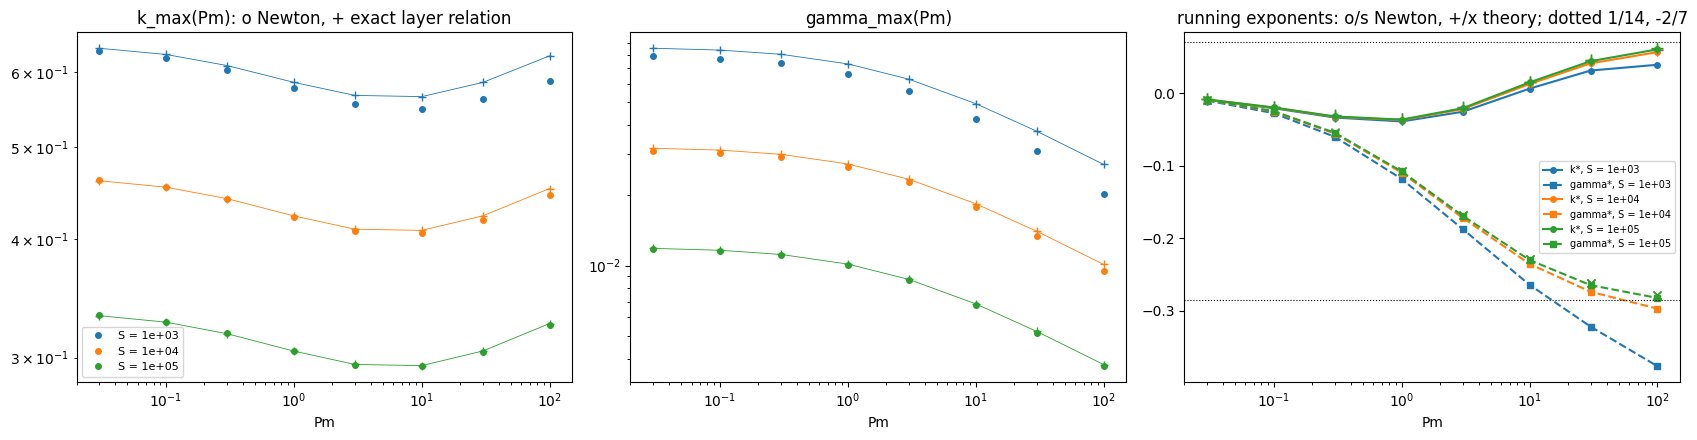

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for j, S in enumerate(V.S_CHAIN):
    Pm = np.array(sorted(KP[S]))
    if not len(Pm):
        continue
    axs[0].loglog(Pm, [KP[S][p]["kmax"] for p in Pm], "o", color=f"C{j}", ms=4, label=f"S = {S:.0e}")
    axs[1].loglog(Pm, [KP[S][p]["gmax"] for p in Pm], "o", color=f"C{j}", ms=4)
    axs[2].semilogx(Pm, [KP[S][p]["slope_k_Pm"] for p in Pm], "o-", color=f"C{j}", ms=4, label=f"k*, S = {S:.0e}")
    axs[2].semilogx(Pm, [KP[S][p]["slope_g_Pm"] for p in Pm], "s--", color=f"C{j}", ms=4, label=f"gamma*, S = {S:.0e}")
    th = [V.theory_kmax_slopes_visc(S, p) for p in Pm]
    axs[2].semilogx(Pm, [t["k_Pm"] for t in th], "+", color=f"C{j}", ms=8)
    axs[2].semilogx(Pm, [t["g_Pm"] for t in th], "x", color=f"C{j}", ms=6)
    th0 = [V.theory_kmax_visc(S, p) for p in Pm]
    axs[0].loglog(Pm, [t[0] for t in th0], "+-", color=f"C{j}", lw=0.6)
    axs[1].loglog(Pm, [t[1] for t in th0], "+-", color=f"C{j}", lw=0.6)
for y in (1/14, -2/7):
    axs[2].axhline(y, color="k", ls=":", lw=0.8)
axs[0].set_title("k_max(Pm): o Newton, + exact layer relation"); axs[1].set_title("gamma_max(Pm)")
axs[2].set_title("running exponents: o/s Newton, +/x theory; dotted 1/14, -2/7")
for ax in axs:
    ax.set_xlabel("Pm")
axs[0].legend(fontsize=8); axs[2].legend(fontsize=7)
plt.tight_layout()

**Result (section 3).** Newton converges in 3–4 iterates at every $(S,P_m)$, $\alpha=0$, and the $n_x/2$ shift of $k^*$ is
$\le5.3\times10^{-6}$ relative. A full Newton at $2n_x$ ($S=10^5$, $P_m=100$) moves $k^*$ by $-4.95\times10^{-11}$.

Against the exact layer relation:

* At $S=10^5$, $k^*/k_{th}=0.99567$–$1.00105$ and $\gamma^*/\gamma_{th}=0.98349$–$0.99264$ over $P_m=0.03$–100.
* At $S=10^3$ the same ratios are 0.94141–0.99397 and 0.74679–0.92199. This is the finite-$S$ correction, largest at large $P_m$.

The running exponents at $P_m=100$, against the exact relation and the large-$P_m$ asymptote:

| $S$ | $d\ln k^*/d\ln P_m$ (measured / theory) | $d\ln\gamma^*/d\ln P_m$ (measured / theory) |
|---|---|---|
| $10^3$ | $+0.03965$ / $+0.06007$ | $-0.37661$ / $-0.27840$ |
| $10^4$ | $+0.05709$ / $+0.06194$ | $-0.29710$ / $-0.27802$ |
| $10^5$ | $+0.06093$ / $+0.06246$ | $-0.28236$ / $-0.27792$ |
| asymptote | $1/14=0.0714$ | $-2/7=-0.2857$ |

Both converge onto the relation as $S$ grows. The relation itself reaches the asymptotes only for $P_m\gg100$.
$k^*$ first falls with $P_m$ and then rises: at $S=10^5$, $k^*=0.29386$ at $P_m=10$ against 0.33255 at $P_m=0.03$ and 0.32452 at $P_m=100$.
At fixed $P_m$ the $S$-exponents stay at the inviscid $n=2$ values: $d\ln k^*/d\ln S=-0.14279$ to $-0.14007$ and
$d\ln\gamma^*/d\ln S=-0.42473$ to $-0.41881$ at $S=10^5$.

### 4. Shear: $k_{max}(\alpha)$, $\gamma_{max}(\alpha)$ at fixed $P_m$, and what viscosity does to the suppression

Continuation in $\alpha$ at fixed $(S,P_m)$, starting from section 3's $\alpha=0$ solution; $P_m=0$ is rung 2's chain on the same box.

In [11]:
def ka_rows(S, Pm):
    if Pm == 0.0:
        return R2KA.get(S, {})
    return KA.get((S, Pm), {})

print("   S      Pm    alpha | k*           gamma*         g*/g*(0) | d ln g*/d ln(1-a^2)  d ln k*/d ln(1-a^2) | "
      "q_Pm(k*)  gamma_nu/gamma_eta | its  grid dk/k  kappa")
for S in sorted({S for S, _ in KA}):
    for Pm in (0.0,) + tuple(sorted(p for s_, p in KA if s_ == S)):
        rows = ka_rows(S, Pm)
        if 0.0 not in rows:
            continue
        g00 = rows[0.0]["gmax"]
        for al, r in sorted(rows.items()):
            if Pm == 0.0 and al not in V.ALPHA_KA:
                continue
            qpm = V.q_Pm(r["rec"]) if Pm > 0 else 0.0
            nr = V.nu_eta_ratio(r["rec"]) if Pm > 0 else np.nan
            print(f"  {S:.0e}  {Pm:5g}  {al:5.3f} | {r['kmax']:.8f}  {r['gmax']:.8e}  {r['gmax']/g00:.5f} | "
                  f"{r['slope_g_u']:+.5f}             {r['slope_k_u']:+.5f}            | {qpm:+.5f}   {nr:+.5f}        | "
                  f"{r['iterations']:2d}   {r['grid_dk']/r['kmax']:+.1e}   {float(r['rec']['kappa']):.1e}")
        print()

   S      Pm    alpha | k*           gamma*         g*/g*(0) | d ln g*/d ln(1-a^2)  d ln k*/d ln(1-a^2) | q_Pm(k*)  gamma_nu/gamma_eta | its  grid dk/k  kappa
  1e+03      0  0.000 | 0.63761256  7.92765475e-02  1.00000 | +nan             +nan            | +0.00000   +nan        |  4   +6.3e-13   6.7e+00
  1e+03      0  0.300 | 0.65097384  7.57172714e-02  0.95510 | +0.49613             -0.20568            | +0.00000   +nan        |  4   +9.0e-14   9.3e+00
  1e+03      0  0.600 | 0.69104641  6.30571187e-02  0.79541 | +0.53819             -0.14086            | +0.00000   +nan        |  4   +8.2e-13   3.0e+01
  1e+03      0  0.800 | 0.73451928  4.58153320e-02  0.57792 | +0.56699             -0.07175            | +0.00000   +nan        |  4   +2.1e-12   1.5e+02
  1e+03      0  0.900 | 0.74391409  3.18224225e-02  0.40141 | +0.56780             +0.05306            | +0.00000   +nan        |  4   -2.1e-11   5.9e+02
  1e+03      0  0.950 | 0.53613862  2.22853139e-02  0.28111 | +0.42058         

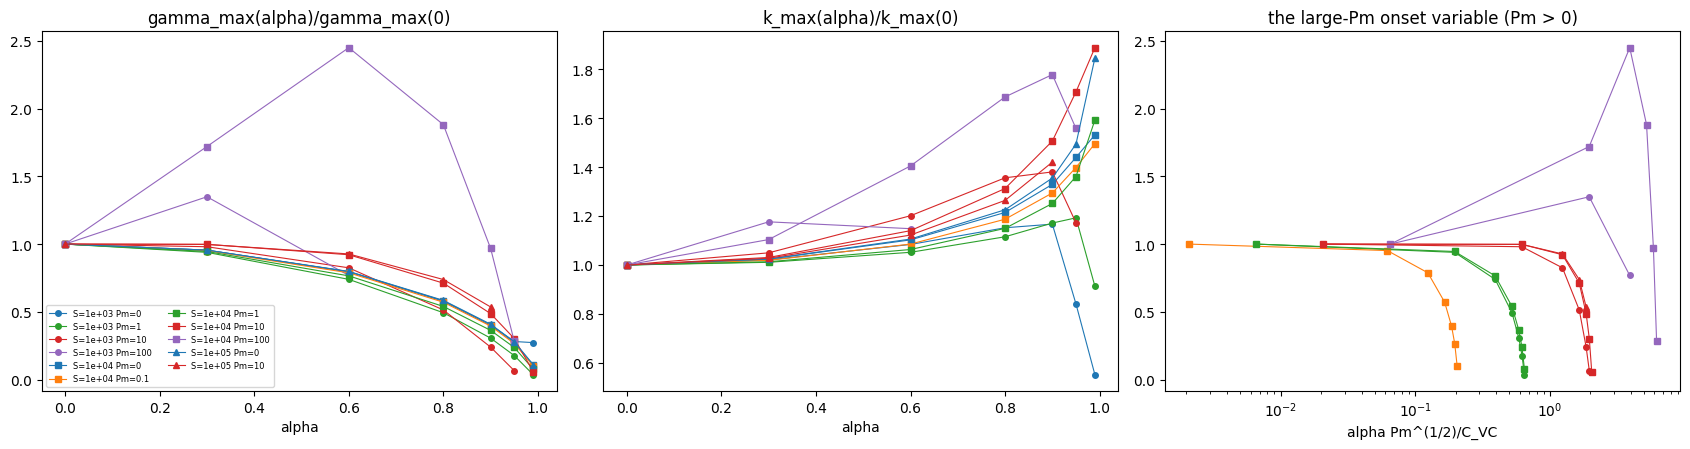

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.6))
mk = {1e3: "o", 1e4: "s", 1e5: "^"}
for S in sorted({S for S, _ in KA}):
    for j, Pm in enumerate((0.0, 0.1, 1.0, 10.0, 100.0)):
        rows = ka_rows(S, Pm)
        if 0.0 not in rows:
            continue
        al = np.array([a for a in sorted(rows) if a in V.ALPHA_KA])
        g = np.array([rows[a]["gmax"] for a in al])/rows[0.0]["gmax"]
        k = np.array([rows[a]["kmax"] for a in al])/rows[0.0]["kmax"]
        lab = f"S={S:.0e} Pm={Pm:g}"
        axs[0].plot(al, g, mk[S] + "-", color=f"C{j}", ms=4, lw=0.8, label=lab)
        axs[1].plot(al, k, mk[S] + "-", color=f"C{j}", ms=4, lw=0.8)
        if Pm > 0:
            axs[2].semilogx(np.maximum(al, 1e-2)*np.sqrt(Pm)/V.c_vcoppi(), g, mk[S] + "-", color=f"C{j}", ms=4, lw=0.8)
axs[0].set_xlabel("alpha"); axs[0].set_title("gamma_max(alpha)/gamma_max(0)"); axs[0].legend(fontsize=6, ncol=2)
axs[1].set_xlabel("alpha"); axs[1].set_title("k_max(alpha)/k_max(0)")
axs[2].set_xlabel("alpha Pm^(1/2)/C_VC"); axs[2].set_title("the large-Pm onset variable (Pm > 0)")
plt.tight_layout()

In [13]:
# the onset of the shear dependence: gamma(k*(0), alpha) = gamma0 (1 - c2 alpha^2 + ...), c2 from the alpha-sensitivity at
# alpha = 0.02, 0.04 (Richardson in alpha^2). Prediction (section 0): c2 -> const as Pm -> 0, c2 ~ Pm at large Pm
print("small-alpha coefficient c2 (gamma_max(alpha)/gamma_max(0) = 1 - c2 alpha^2 + ...)")
print("    S      Pm   | c2(0.02)    c2(0.04)    c2 (extrap.) | c2/c2(Pm=0)  c2/Pm    | d ln c2/d ln Pm (neighbours)")
for S in V.S_CHAIN:
    pms = [p for p in V.PM_C2 if (S, p) in C2]
    for i, p in enumerate(pms):
        r = C2[(S, p)]
        c20 = C2[(S, 0.0)]["c2"] if (S, 0.0) in C2 else np.nan
        sl = (np.log(C2[(S, pms[i + 1])]["c2"]/C2[(S, pms[i - 1])]["c2"])/np.log(pms[i + 1]/pms[i - 1])
              if 1 < i < len(pms) - 1 else np.nan)
        print(f"  {S:.0e}  {p:5g} | {r['c2_alpha'][0]:.6f}   {r['c2_alpha'][1]:.6f}   {r['c2']:.6f}     | "
              f"{r['c2']/c20:8.3f}    {r['c2']/p if p else np.nan:7.4f}  | {sl:+.3f}")

small-alpha coefficient c2 (gamma_max(alpha)/gamma_max(0) = 1 - c2 alpha^2 + ...)
    S      Pm   | c2(0.02)    c2(0.04)    c2 (extrap.) | c2/c2(Pm=0)  c2/Pm    | d ln c2/d ln Pm (neighbours)
  1e+03      0 | 0.477436   0.478372   0.477124     |    1.000        nan  | +nan
  1e+03   0.03 | 0.496155   0.497029   0.495863     |    1.039    16.5288  | +nan
  1e+03    0.1 | 0.529366   0.530181   0.529095     |    1.109     5.2909  | +0.074
  1e+03    0.3 | 0.587650   0.588443   0.587385     |    1.231     1.9579  | +0.100
  1e+03      1 | 0.666575   0.667444   0.666286     |    1.396     0.6663  | +0.047
  1e+03      3 | 0.654766   0.655822   0.654414     |    1.372     0.2181  | -0.742
  1e+03     10 | 0.121838   0.125026   0.120775     |    0.253     0.0121  | +nan
  1e+03     30 | -1.895422   -1.868223   -1.904489     |   -3.992    -0.0635  | +nan
  1e+03    100 | -7.948684   -7.675561   -8.039726     |  -16.850    -0.0804  | +nan
  1e+04      0 | 0.478551   0.479465   0.478247     |   

/var/folders/c1/mrll_5zs01j4m9bz9ryks59h0000gn/T/ipykernel_25135/3719762258.py:10: RuntimeWarning: invalid value encountered in log
  sl = (np.log(C2[(S, pms[i + 1])]["c2"]/C2[(S, pms[i - 1])]["c2"])/np.log(pms[i + 1]/pms[i - 1])


In [14]:
# the S-exponent of gamma_max at fixed Pm across alpha (positive: gamma_max GROWS with S at fixed Pm)
print("d ln gamma*/d ln S |_Pm and d ln gamma*/d ln Pm |_S at k*(alpha) (envelope, one solve each)")
for S in sorted({S for S, _ in KA}):
    print(f"  S = {S:.0e}:  alpha " + " ".join(f"{a:>7g}" for a in V.ALPHA_KA))
    for Pm in (0.0,) + tuple(sorted(p for s_, p in KA if s_ == S)):
        rows = ka_rows(S, Pm)
        print(f"    Pm={Pm:<5g} q_S  " + " ".join(f"{rows[a]['slope_g_S']:+7.3f}" if a in rows else "      -"
                                         for a in V.ALPHA_KA))
        if Pm > 0:
            print(f"    {'':8s} q_Pm " + " ".join(f"{rows[a]['slope_g_Pm']:+7.3f}" if a in rows else "      -"
                                             for a in V.ALPHA_KA))

d ln gamma*/d ln S |_Pm and d ln gamma*/d ln Pm |_S at k*(alpha) (envelope, one solve each)
  S = 1e+03:  alpha       0     0.3     0.6     0.8     0.9    0.95    0.99
    Pm=0     q_S   -0.385  -0.386  -0.386  -0.388  -0.400  -0.525  -0.751
    Pm=1     q_S   -0.373  -0.368  -0.347  -0.304  -0.241  -0.153  +0.121
             q_Pm  -0.118  -0.123  -0.144  -0.188  -0.261  -0.383  -1.280
    Pm=10    q_S   -0.337  -0.313  -0.216  -0.009  +0.397  +1.644       -
             q_Pm  -0.264  -0.194  -0.100  -0.176  -0.507  -1.723       -
    Pm=100   q_S   -0.227  +0.094  +1.442       -       -       -       -
             q_Pm  -0.377  -0.284  -1.475       -       -       -       -
  S = 1e+04:  alpha       0     0.3     0.6     0.8     0.9    0.95    0.99
    Pm=0     q_S   -0.416  -0.416  -0.415  -0.412  -0.409  -0.405  -0.421
    Pm=0.1   q_S   -0.415  -0.415  -0.413  -0.409  -0.404  -0.398  -0.400
             q_Pm  -0.025  -0.028  -0.034  -0.041  -0.046  -0.051  -0.073
    Pm=1     q_S

In [15]:
# the viscous stability boundary alpha_c: bisection in alpha on the sign of max_k (largest REAL eigenvalue) of the dense
# block on the k_max box, nx = 1024, re-evaluated at 2 nx at the final bracket (V.alpha_c_bisect, cached phase "alpha_c");
# against the one-Newton-step estimate from the last growing k_max solution of the alpha chain
AC = V.alpha_c_results()
print("    S      Pm      nu   | bisection bracket      linear root | 1 - alpha_c^2 | G(lo), G(hi) at 2 nx  | Newton step (chain end)")
for (S, Pm), r in sorted(AC.items()):
    rows = KA.get((S, Pm), {})
    als = [a for a in sorted(rows) if a in V.ALPHA_KA]
    nst = np.nan
    if als and 0 < len(als) < len(V.ALPHA_KA):
        ga = complex(rows[als[-1]]["rec"]["dlam_alpha"]).real
        nst = als[-1] - rows[als[-1]]["gmax"]/ga if ga < 0 else np.nan
    ac = r["alpha_c_lin"]
    print(f"  {S:.0e}  {Pm:6g}  {Pm/S:5.0e} | [{r['lo']:.5f}, {r['hi']:.5f}]     {ac:.5f}   |    {1 - ac*ac:.4f}     | "
          f"{r['g_lo_2nx']:+.2e} {r['g_hi_2nx']:+.2e} | " + (f"{nst:.4f} (1 - a^2 = {1 - nst*nst:.4f})" if np.isfinite(nst) else "-"))
one = lambda S, Pm: 1 - AC[(S, Pm)]["alpha_c_lin"]**2
if all(k in AC for k in ((1e3, 10.0), (1e4, 100.0), (1e3, 100.0), (1e4, 1000.0))):
    print(f"\nsame nu: 1e-2: {one(1e3, 10.0):.4f} vs {one(1e4, 100.0):.4f} (ratio {one(1e4, 100.0)/one(1e3, 10.0):.3f}); "
          f"0.1: {one(1e3, 100.0):.4f} vs {one(1e4, 1000.0):.4f} (ratio {one(1e4, 1000.0)/one(1e3, 100.0):.3f})")
    print(f"10x nu: x{one(1e3, 100.0)/one(1e3, 10.0):.2f} (S = 1e3), x{one(1e4, 1000.0)/one(1e4, 100.0):.2f} (S = 1e4); "
          f"scaling 3's Pm^(7/6)/S would differ by x{(100/10)**(7/6)/10:.3f} between same-nu pairs")

    S      Pm      nu   | bisection bracket      linear root | 1 - alpha_c^2 | G(lo), G(hi) at 2 nx  | Newton step (chain end)
  1e+03      10  1e-02 | [0.96969, 0.97000]     0.96996   |    0.0592     | +4.09e-05 -9.91e-06 | 0.9688 (1 - a^2 = 0.0614)
  1e+03     100  1e-01 | [0.72969, 0.73125]     0.73053   |    0.4663     | +1.55e-04 -4.00e-05 | 0.7620 (1 - a^2 = 0.4193)
  1e+04     100  1e-02 | [0.96844, 0.96875]     0.96858   |    0.0619     | +2.54e-05 -3.14e-06 | 0.9689 (1 - a^2 = 0.0611)
  1e+04    1000  1e-01 | [0.72969, 0.73125]     0.72975   |    0.4675     | +1.43e-05 -3.10e-06 | -

same nu: 1e-2: 0.0592 vs 0.0619 (ratio 1.045); 0.1: 0.4663 vs 0.4675 (ratio 1.002)
10x nu: x7.88 (S = 1e3), x7.56 (S = 1e4); scaling 3's Pm^(7/6)/S would differ by x1.468 between same-nu pairs


In [16]:
# the Pm chain with shear, (S, alpha) = CHAIN_SHEAR, against alpha = 0 at the same S
for (S, al), rows in KPS.items():
    print(f"S = {S:.0e}, alpha = {al}: k_max(Pm), gamma_max(Pm) and the Pm exponents, against alpha = 0")
    print("    Pm   | k*           gamma*        g*/g*(alpha=0) | dlnk*/dlnPm  dlng*/dlnPm (alpha=0: same) | its grid dk/k")
    for Pm, r in sorted(rows.items()):
        r0 = KP.get(S, {}).get(Pm)
        print(f"  {Pm:6g} | {r['kmax']:.8f}  {r['gmax']:.8e}  {r['gmax']/r0['gmax'] if r0 else np.nan:.5f}         | "
              f"{r['slope_k_Pm']:+.5f}     {r['slope_g_Pm']:+.5f} ({r0['slope_g_Pm'] if r0 else np.nan:+.5f})   | "
              f"{r['iterations']:2d}  {r['grid_dk']/r['kmax']:+.1e}")
for (S, al, Pm), D in sorted(DISPS.items()):
    ka, recs = curve(D)
    if len(ka):
        print(f"\nS = {S:.0e}, alpha = {al}, Pm = {Pm:g}: ka   " + " ".join(f"{k:6.2f}" for k in ka))
        print(f"{'':31s}q_Pm " + " ".join(f"{V.q_Pm(r):+6.3f}" for r in recs))
        print(f"{'':31s}q_S  " + " ".join(f"{V.q_S(r):+6.3f}" for r in recs))
        r0 = DISP.get((S, Pm), {}).get(1, {})
        print(f"{'':31s}g/g(a=0) " + " ".join(f"{complex(r['lam']).real/complex(r0[k]['lam']).real:6.3f}" if k in r0 else "   -  "
                                             for k, r in zip(ka, recs)))

S = 1e+04, alpha = 0.9: k_max(Pm), gamma_max(Pm) and the Pm exponents, against alpha = 0
    Pm   | k*           gamma*        g*/g*(alpha=0) | dlnk*/dlnPm  dlng*/dlnPm (alpha=0: same) | its grid dk/k
    0.03 | 0.60732405  1.24333328e-02  0.40098         | -0.01714     -0.01611 (-0.00891)   |  5  -1.5e-12
     0.1 | 0.58720293  1.20094791e-02  0.39474         | -0.04053     -0.04581 (-0.02500)   |  4  -9.7e-14
     0.3 | 0.55562880  1.11269734e-02  0.38161         | -0.05553     -0.09602 (-0.05533)   |  4  +1.2e-13
       1 | 0.52842906  9.61298919e-03  0.36329         | -0.01569     -0.13643 (-0.10937)   |  4  -1.4e-14
       3 | 0.54116699  8.48174424e-03  0.37387         | +0.06055     -0.06899 (-0.17178)   |  4  -1.2e-12
      10 | 0.61110912  8.63295429e-03  0.48705         | +0.13778     +0.09559 (-0.23537)   |  5  -3.5e-12
      30 | 0.72185587  9.83997358e-03  0.73568         | +0.14640     +0.10102 (-0.27378)   |  4  -9.7e-13
     100 | 0.79093973  9.16599268e-03  0.96765    

**Result (section 4). Viscosity changes the $\alpha$-dependence qualitatively. There are three regimes in $P_m$, and each
scaling argument of section 0 matches one of them.**

* **$P_m\lesssim1$: suppression stronger than inviscid.** At $S=10^4$, $P_m=1$, $\gamma^*(0.9)/\gamma^*(0)=0.36329$ against
  0.40395 at $P_m=0$. $q_{P_m}$ at $k^*$ grows more negative with $\alpha$, from $-0.10937$ at $\alpha=0$ to $-0.27704$ at
  $\alpha=0.99$.
* **$P_m\sim10$: suppression weaker, and $\nu$ raises $\gamma$.** At $S=10^4$, $\gamma^*(0.8)/\gamma^*(0)=0.71185$ against
  0.58127 inviscid, and $q_{P_m}$ is $\approx0$ at $\alpha=0.6$ ($+0.00070$) and positive at $\alpha=0.8$–0.95 ($+0.08810$, $+0.09559$, $+0.04375$). At
  $S=10^5$, $q_{P_m}=+0.09674$ at $\alpha=0.8$. This is scaling 1's sign: in the shear-dominated layer viscosity widens the
  layer like resistivity. Its weight is small, though: $\gamma_\nu/\gamma_\eta\le0.053$, not $O(1)$. $q_{P_m}$ stays below 1/3.
* **$P_m\sim100$: shear DESTABILISES.** At $S=10^4$, $\gamma^*(\alpha)/\gamma^*(0)$ is 1.71976, 2.44905, 1.88102, 0.96765
  and 0.28208 at $\alpha=0.3$, 0.6, 0.8, 0.9 and 0.95. At $\alpha=0.6$ the shear flow lifts $\gamma_{max}$ from its viscous
  value $9.47\times10^{-3}$ to $2.32\times10^{-2}$, close to the inviscid $2.49\times10^{-2}$ at that $\alpha$. At $S=10^3$:
  1.34898 at $\alpha=0.3$.
  An independent route reproduces this (review, 2026-10-02): a `Parameters` built directly at $(L_y,\nu,\eta)$, no overrides,
  dense `numpy` eigenvalues, gives $\gamma^*=9.4723968\times10^{-3}$ ($\alpha=0$) and $2.3198354\times10^{-2}$ ($\alpha=0.6$) to $10^{-9}$,
  unchanged at $n_x=1024$–4096 and at $2L_x$. A $k$ scan over $ka\in[0.05,2.2]$ shows one maximum, so this is the global one.
  The growing eigenvalue is real and has tearing parity ($\psi(-x)=\bar\psi(x)$ to $10^{-14}$, $\psi(0)\ne0$).

The small-$\alpha$ coefficient $c_2$ (scaling 2) shows where the change sets in. $c_2$ rises mildly from 0.478 ($P_m=0$) to
0.597 ($P_m=1$, $S=10^4$), changes sign between $P_m=3$ and 10 at $S=10^4,10^5$ (between 10 and 30 at $S=10^3$), and then grows roughly $\propto P_m$: the local exponent between $P_m=30$ and 100 is 1.2–1.3, and $c_2/P_m$ is still drifting
($-0.0635\to-0.0804$, $-0.0715\to-0.1031$, $-0.0618\to-0.0867$ at $S=10^3,10^4,10^5$). Finite-$\alpha$ dense eigenvalues at
$k^*(0)$ reproduce $c_2$ at $S=10^4$ ($0.53080$, $-0.04433$, $-10.307$ at $P_m=3$, 10, 100). So the shear sets in at roughly
$\alpha\sim P_m^{-1/2}$, as scaling 2 has it, but it destabilises. Scaling 2 gave the onset, not the sign.

**Viscous stabilisation below $\alpha=1$ (scaling 3).** At $\nu=0$ the mode grows up to $\alpha=1$. With viscosity the
$\alpha$-chains end:

* at $S=10^3$: at $\alpha=0.99$ for $P_m=10$ and at $\alpha=0.8$ for $P_m=100$;
* at $S=10^4$: at $\alpha=0.99$ for $P_m=100$.

No growing $k_{max}$ is found there. Section 5's dense scans over $ka\in[0.1,1.6]$ find no real growing mode at $\alpha=0.99$
($S=10^3$, $P_m=10$), at $\alpha=0.95$ and 0.99 ($S=10^3$, $P_m=100$), or at $\alpha=0.99$ ($S=10^4$, $P_m=100$; there only a weak
complex pair at $ka=0.1$). The boundary is located by bisection in $\alpha$ on the sign of $\max_k$ of the largest REAL
eigenvalue of the dense block ($n_x=1024$, $k_{max}$ box; the cell above, phase `alpha_c`). Near $\alpha_c$, $\gamma_{max}(\alpha)$ is
close to linear, so the last two growing evaluations give a linear root inside the bracket. Re-evaluated at $2n_x$, the
bracket ends keep their signs and change by $\le10^{-8}$ relative:

| $(S,P_m)$ | $\nu$ | bracket | $\alpha_c$ (linear root) | $1-\alpha_c^2$ | one Newton step from the chain end |
|---|---|---|---|---|---|
| $(10^3,10)$ | $10^{-2}$ | [0.96969, 0.97000] | 0.96996 | 0.0592 | 0.9688 (0.0614) |
| $(10^4,100)$ | $10^{-2}$ | [0.96844, 0.96875] | 0.96858 | 0.0619 | 0.9689 (0.0611) |
| $(10^3,100)$ | $10^{-1}$ | [0.72969, 0.73125] | 0.73053 | 0.4663 | 0.7620 (0.4193) |
| $(10^4,1000)$ | $10^{-1}$ | [0.72969, 0.73125] | 0.72975 | 0.4675 | -- |

The one-Newton-step estimates were good to $10^{-3}$ in $\alpha_c$ at $\nu=10^{-2}$ but $0.03$ off at $\nu=0.1$, where
$\gamma_{max}(\alpha)$ is strongly curved between the last chain point (0.6) and the boundary.

Pairs at the same $\nu=P_m/S$ agree to $\lesssim5\%$ in $1-\alpha_c^2$: 0.0592 against 0.0619 at $\nu=10^{-2}$ (4.5%), 0.4663
against 0.4675 at $\nu=0.1$ (0.2%; the $(10^4,1000)$ point was added for this check). Scaling 3's $P_m^{7/6}/S$ would make each pair
differ by 1.47×. **So the boundary depends mainly on $\nu$ in this window** (two $\nu$ values, two $S$ each), with $1-\alpha_c^2$
growing 7.6–7.9× for 10× $\nu$. As scaling 3 requires,
$\gamma_{max}$ grows with $S$ at fixed $P_m$ near the boundary: $q_S=+0.397$, $+1.644$ at $S=10^3$, $P_m=10$, $\alpha=0.9$, 0.95;
$+0.329$, $+1.637$ at $S=10^4$, $P_m=100$. At $\nu=0$, $q_S\approx-0.4$ everywhere.

The $P_m$-chain at $\alpha=0.9$, $S=10^4$ shows the competition in one curve:

* $\gamma^*$ falls from $1.243\times10^{-2}$ ($P_m=0.03$) to $8.48\times10^{-3}$ ($P_m=3$);
* it then rises to $9.84\times10^{-3}$ ($P_m=30$, $d\ln\gamma^*/d\ln P_m=+0.10102$);
* it falls again at $P_m=100$ ($-0.34192$), where the outer viscous damping takes over.

### 5. The low-$k$ maximum at $\alpha\gtrsim0.95$

Rung 2 found that at $\alpha\gtrsim0.95$ and low $S$ the maximum of $\gamma(k)$ moves to low $k$. `tearing-lowk-branch.ipynb` (section 7)
shows that at $S\le2\times10^3$ this is a single maximum migrating across a flat top; two distinct maxima appear only from
$S\sim5\times10^3$. The continuation clips seeds to $[k^*/2,2k^*]$ (`R._trust`), so a fast move or a switch shows as a jump in $k^*$. Coarse dense scans
($n_x=1024$, the $k_{max}$ box; eigenvalue of largest real part per $k$) show which maxima exist at each $P_m$.

local maxima of the coarse dense gamma(k) (k grid [0.1 1.6] , 21 points):
  S=1e+03 alpha=0.95 Pm=     0: local maxima at ka = [0.5278]; global 0.5278 (gamma 2.2285e-02); growing modes per k <= 1
  S=1e+03 alpha=0.95 Pm=   0.1: local maxima at ka = [0.60629]; global 0.6063 (gamma 2.0221e-02); growing modes per k <= 1
  S=1e+03 alpha=0.95 Pm=     1: local maxima at ka = [0.69644]; global 0.6964 (gamma 1.1721e-02); growing modes per k <= 1
  S=1e+03 alpha=0.95 Pm=    10: local maxima at ka = [0.60629]; global 0.6063 (gamma 2.7939e-03); growing modes per k <= 1
  S=1e+03 alpha=0.95 Pm=   100: NO real growing mode at any ka of the grid; largest Re lambda -2.634e-05 at ka = 0.100
  S=1e+03 alpha=0.99 Pm=     0: local maxima at ka = [0.34822]; global 0.3482 (gamma 2.1639e-02); growing modes per k <= 23
  S=1e+03 alpha=0.99 Pm=   0.1: local maxima at ka = [0.34822]; global 0.3482 (gamma 1.8873e-02); growing modes per k <= 1
  S=1e+03 alpha=0.99 Pm=     1: local maxima at ka = [0.5278]; global

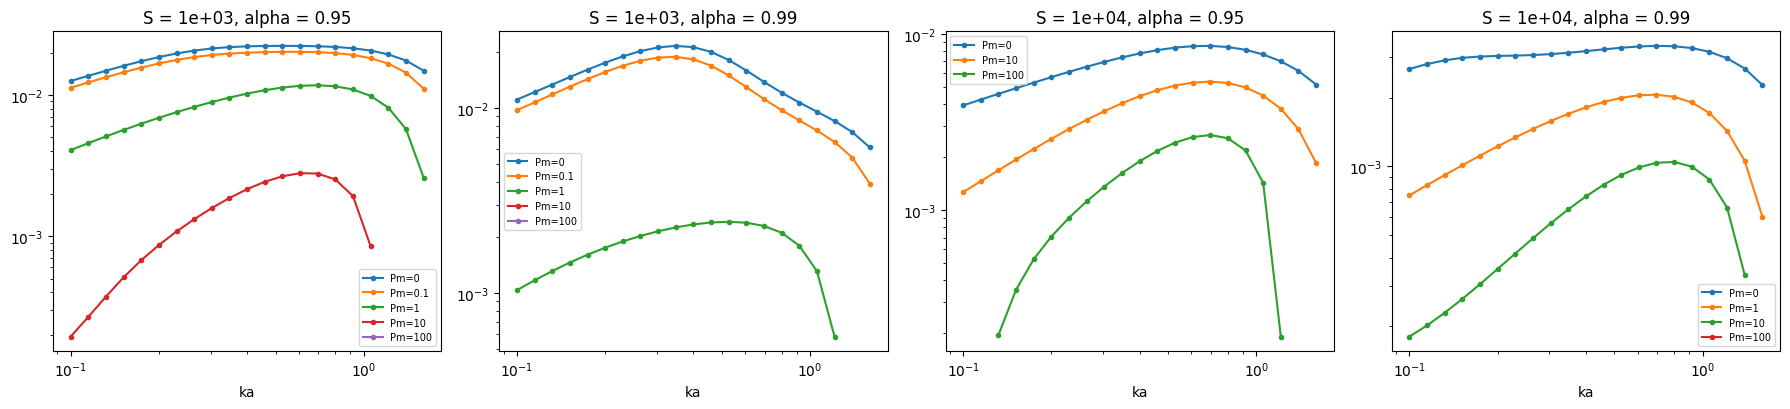

In [17]:
fig, axs = plt.subplots(1, len({(S, al) for S, al, _ in BR}), figsize=(18, 4.2), squeeze=False)
panels = sorted({(S, al) for S, al, _ in BR})
print("local maxima of the coarse dense gamma(k) (k grid", np.round(V.KA_BRANCH, 3)[[0, -1]], ", 21 points):")
for ax, (S, al) in zip(axs[0], panels):
    for j, Pm in enumerate(sorted(p for s_, a_, p in BR if (s_, a_) == (S, al))):
        ks, g, second, npos, top = BR[(S, al, Pm)]
        ax.loglog(ks, g, "o-", ms=3, color=f"C{j}", label=f"Pm={Pm:g}")
        lm = V.local_maxima(ks, g)
        if np.isfinite(g).any():
            i = int(np.nanargmax(g))
            print(f"  S={S:.0e} alpha={al} Pm={Pm:6g}: local maxima at ka = {lm}; global {ks[i]:.4f} (gamma {g[i]:.4e}); "
                  f"growing modes per k <= {npos.max()}")
        else:
            j = int(np.nanargmax(top))
            print(f"  S={S:.0e} alpha={al} Pm={Pm:6g}: NO real growing mode at any ka of the grid; largest Re lambda "
                  f"{top[j]:+.3e} at ka = {ks[j]:.3f}" + (" (a complex pair: overstable)" if top[j] > 0 else ""))
        weak = [(k, t) for k, t, gg in zip(ks, top, g) if t > 0 and (not np.isfinite(gg))]
        if weak and np.isfinite(g).any():
            print(f"      + complex growing pairs (Re > 0) at ka = {[round(float(k), 3) for k, _ in weak]}")
    ax.set_title(f"S = {S:.0e}, alpha = {al}"); ax.set_xlabel("ka"); ax.legend(fontsize=7)
plt.tight_layout()

In [18]:
# jumps in the alpha chains: |ln(k*_i/k*_{i-1})| > ln 1.3 between neighbouring alpha
print("k* jumps along the alpha chains (|ratio| > 1.3) -- possible branch switches:")
found = False
for (S, Pm), rows in sorted(KA.items()):
    al = sorted(rows)
    for a, b in zip(al[:-1], al[1:]):
        rr = rows[b]["kmax"]/rows[a]["kmax"]
        if abs(np.log(rr)) > np.log(1.3):
            found = True
            print(f"  S={S:.0e} Pm={Pm:g}: alpha {a} -> {b}: k* {rows[a]['kmax']:.4f} -> {rows[b]['kmax']:.4f} "
                  f"(seed {rows[b]['k0']:.4f}, {rows[b]['iterations']} its)")
print("  none" if not found else "")

k* jumps along the alpha chains (|ratio| > 1.3) -- possible branch switches:
  S=1e+03 Pm=1: alpha 0.95 -> 0.99: k* 0.6872 -> 0.5264 (seed 0.6818, 6 its)



**Result (section 5).**

* No scan on this 21-point grid shows two local maxima. At $S=10^3$, $\alpha=0.99$ there is ONE maximum, and it moves with $P_m$:
  $ka=0.348$ (rung 2's low-$k$ position) at $P_m=0$ and 0.1, 0.528 at $P_m=1$, none at $P_m\ge10$. This is one maximum moving, not a
  switch between two: `tearing-lowk-branch.ipynb` (section 7) finds that at $S\le2\times10^3$ the low-$k$ and high-$k$ maxima never
  coexist (a single maximum migrates across a flat top), and two distinct maxima appear only from $S\sim5\times10^3$. The
  viscosity at which the maximum leaves the low-$k$ position ($P_m$ between 0.1 and 1, i.e. $\nu$ between $0.1/S$ and $1/S$) rests
  on this one $(S,\alpha)$ and three $P_m$ values; it is not established in general.
* The one $k^*$ jump in the chains (>1.3×), $S=10^3$, $P_m=1$, $\alpha$ 0.95→0.99 ($k^*$ 0.6872→0.5264), is that single maximum
  moving. The scan at $\alpha=0.99$, $P_m=1$ has its only maximum at 0.528.
* At $S=10^4$, $P_m=100$ the coarse grid also shows weak complex growing pairs at the lowest $ka$ ($\le0.115$; the box holds
  only ~5 wavelengths there). They are $\ge10\times$ slower than the tearing maximum at $\alpha=0.95$. At $\alpha=0.99$ they are
  the only growing modes, with $\mathrm{Re}\,\lambda=5.3\times10^{-5}$ at $ka=0.1$. They are not grid- or box-checked and not part of
  the results above.

### 6. Summary

1. **Exact layer theory at $\alpha=0$.** The visco-resistive inner layer was solved exactly (6th-order BVP). Its limits are B&L
   as $P_m\to0$ and Porcelli's viscous constant-$\psi$ / nonconstant-$\psi$ regimes as $P_m\to\infty$, with
   $I_V=\pi6^{-1/3}\Gamma(5/6)/\Gamma(7/6)$ and $C_{VC}=1.5255$. For this $n=2$ sheet, $k_{max}\propto S^{-1/7}P_m^{1/14}$ and
   $\gamma_{max}\propto S^{-3/7}P_m^{-2/7}$.
2. **The eigen-solves converge onto it as $S$ grows.** At $S=10^5$, $\gamma^*/\gamma_{th}\ge0.98349$ and the
   $d\ln\gamma^*/d\ln P_m$ gap is $\le0.0044$ at every $P_m$. The $P_m$-exponents are $+0.06093$ / $-0.28236$ at $P_m=100$,
   against the asymptotes $1/14$, $-2/7$. FD gates for $\partial_\nu$, $\partial_\eta$ and $\partial_k$ are at order 2.000.
3. **With shear, viscosity changes the $\alpha$-dependence qualitatively.**
   - For $P_m\lesssim1$ it deepens the suppression.
   - For $P_m\sim10$ it weakens the suppression, and $q_{P_m}>0$ (up to $+0.142$).
   - For $P_m\sim100$ the shear flow raises $\gamma_{max}$, by 2.45× at $\alpha=0.6$ ($S=10^4$; the largest on the $\alpha$ grid,
     confirmed by an independent dense route). The small-$\alpha$ coefficient changes sign between $P_m=3$ and 30, then grows
     roughly like $-P_m$ (local exponent 1.2–1.3 at $P_m=30$–100; $c_2/P_m\approx-0.08$ to $-0.10$ at $P_m=100$): onset at roughly
     $\alpha\sim P_m^{-1/2}$.
4. **Viscosity stabilises shear tearing below $\alpha=1$.** By bisection, $1-\alpha_c^2=0.059$–0.062 at $\nu=10^{-2}$ and 0.466–0.467
   at $\nu=0.1$ ($S=10^3$ and $10^4$ each): it depends mainly on $\nu$ in this window (pairs at fixed $\nu$ agree to $\lesssim5\%$). Near it $\gamma_{max}$ grows with $S$ ($q_S$ up to $+1.64$).

**Not settled:**

* No theory for the shear+viscosity layer (items 1–3 of section 0 are scaling arguments). Scaling 1 has the right sign but its
  weight $c$ is $\ll1$. Scaling 3's $P_m^{7/6}/S$ fails; the data say mainly $\nu$.
* $\alpha_c$ is bracketed to $3\times10^{-4}$ at $\nu=10^{-2}$ and $1.6\times10^{-3}$ at $\nu=0.1$, at four points and two $\nu$; whether
  the boundary is a function of $\nu$ alone needs more $\nu$ values and a wider $S$ range.
* The weak complex low-$k$ modes at $S=10^4$, $P_m=100$, $\alpha\ge0.95$ are unidentified.
* $S\ge10^5$ with shear was run only at $P_m=10$, $\alpha\le0.9$.